# Where to put the bins: uniform vs range-adapted

A small, visual notebook to understand (and to take figures for the slides of) one idea of week 2:

> In Lab and YCrCb, the colour channels only use a **narrow part** of the 0–255 scale. If we split 0–255 into equal bins,
> most bins are **empty** and the histogram cannot tell colours apart. If we split only the part that is really used
> (**range-adapted bins**), every bin is useful.

1. Where are the values of each channel? (the problem)
2. What are percentiles, and how we use them to find "the part that is really used"
3. Uniform vs range-adapted bins on the same data
4. What the histogram "sees": the painting re-coloured with the colour of its bin
5. Effect on a real 3D histogram (empty cells)
6. Effect on retrieval (results of `c1-week2.ipynb`, §3.3)

All figures are also saved in `figures/ranges_*.png`. Put this notebook in `Project/week2/`.

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle

TEAL, ORANGE, GREY, RED, INK = "#1B7F79", "#F0A830", "#9AA5AB", "#C8553D", "#222222"
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"})
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
EPS = 1e-10


def find_dir(*candidates, pattern="*.jpg"):
    for c in map(Path, candidates):
        if c.is_dir():
            if any(c.glob(pattern)):
                return c
            for sub in sorted(p for p in c.iterdir() if p.is_dir()):
                if any(sub.glob(pattern)):
                    return sub
    return None


BBDD_DIR = find_dir("../week1/BBDD", "BBDD", pattern="bbdd_*.jpg")
QSD1_DIR = find_dir("qsd1_w2", "qsd1_w1")


def resize_max(img, max_side=400):
    s = max_side / max(img.shape[:2])
    return cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else img


def channel_mean_128(img):
    """Illumination normalisation used in the project (each B, G, R channel scaled to mean 128)."""
    f = img.astype(np.float32)
    return np.clip(f * (128 / (f.reshape(-1, 3).mean(0) + EPS)), 0, 255).astype(np.uint8)


BBDD = [channel_mean_128(resize_max(cv2.imread(str(p)))) for p in sorted(BBDD_DIR.glob("bbdd_*.jpg"))]
LAB_PIX = np.concatenate([cv2.cvtColor(x, cv2.COLOR_BGR2LAB).reshape(-1, 3) for x in BBDD]).astype(float)
YCC_PIX = np.concatenate([cv2.cvtColor(x, cv2.COLOR_BGR2YCrCb).reshape(-1, 3) for x in BBDD]).astype(float)
print(f"{len(BBDD)} BBDD paintings, {len(LAB_PIX):,} pixels")

287 BBDD paintings, 35,435,882 pixels


## 1. The problem: where are the values?

In OpenCV, every channel of Lab and YCrCb is stored as a number from 0 to 255. For the **colour** channels (a and b in
Lab, Cr and Cb in YCrCb), 128 means "no colour" (grey), and the further from 128, the more saturated the colour.

Paintings are not made of fluorescent colours, so almost all their pixels have colour values **close to 128**. The strip
under each plot shows which colour each value of the channel represents.

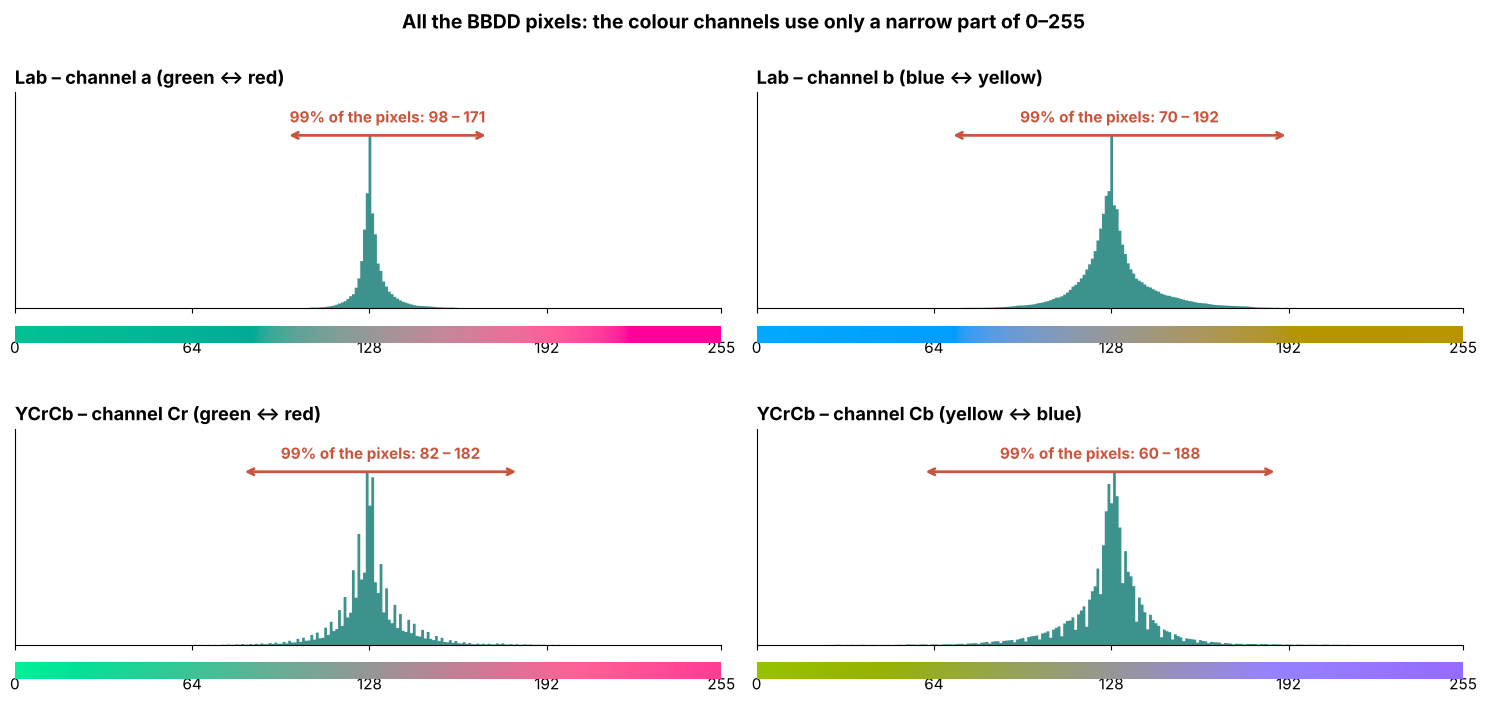

In [2]:
def colour_strip(space, channel, n=256):
    """RGB colours along one channel (the other channels fixed at a mid value)."""
    v = np.full((1, n, 3), 128, np.uint8)
    v[0, :, 0] = 160 if space == "LAB" else 150           # a fairly light brightness so colours are visible
    v[0, :, channel] = np.linspace(0, 255, n).astype(np.uint8)
    code = cv2.COLOR_LAB2RGB if space == "LAB" else cv2.COLOR_YCrCb2RGB
    return cv2.cvtColor(v, code)


def channel_plot(ax, values, space, channel, name, edges=None, edge_color=None, show_pct=False):
    hist, _ = np.histogram(values, bins=256, range=(0, 256))
    hist = hist / hist.sum()
    ax.fill_between(np.arange(256), hist, color=TEAL, alpha=0.85, step="mid", lw=0)
    top = hist.max() * 1.25
    if edges is not None:
        inner = np.clip(edges, 0, 256)
        for k, (a, b) in enumerate(zip(inner[:-1], inner[1:])):
            ax.axvspan(a, b, color=GREY if k % 2 else "white", alpha=0.18, lw=0)
            if show_pct:
                pct = ((values >= edges[k]) & (values < edges[k + 1])).mean()
                if pct >= 0.005:
                    narrow = (b - a) < 14
                    ax.text((a + b) / 2, top * (0.80 if narrow else 0.93), f"{pct:.0%}", ha="center", fontsize=8 if narrow else 9,
                            color=INK, fontweight="bold", rotation=90 if narrow else 0)
        for e in inner[1:-1]:
            ax.axvline(e, color=edge_color or INK, lw=1.4)
    ax.set_xlim(0, 255); ax.set_ylim(0, top); ax.set_yticks([])
    ax.set_title(name, loc="left")
    strip = ax.inset_axes([0, -0.16, 1, 0.08])
    strip.imshow(colour_strip(space, channel), aspect="auto", extent=(0, 255, 0, 1)); strip.axis("off")
    ax.set_xticks([0, 64, 128, 192, 255]); ax.tick_params(axis="x", pad=18)


fig, axes = plt.subplots(2, 2, figsize=(15, 7))
for ax, (pix, space, c, name) in zip(axes.ravel(), [(LAB_PIX, "LAB", 1, "Lab – channel a (green ↔ red)"),
                                                    (LAB_PIX, "LAB", 2, "Lab – channel b (blue ↔ yellow)"),
                                                    (YCC_PIX, "YCRCB", 1, "YCrCb – channel Cr (green ↔ red)"),
                                                    (YCC_PIX, "YCRCB", 2, "YCrCb – channel Cb (yellow ↔ blue)")]):
    channel_plot(ax, pix[:, c], space, c, name)
    lo, hi = np.percentile(pix[:, c], [0.5, 99.5])
    ax.annotate("", xy=(lo, ax.get_ylim()[1] * 0.8), xytext=(hi, ax.get_ylim()[1] * 0.8),
                arrowprops=dict(arrowstyle="<->", color=RED, lw=2))
    ax.text((lo + hi) / 2, ax.get_ylim()[1] * 0.86, f"99% of the pixels: {lo:.0f} – {hi:.0f}", ha="center", color=RED, fontweight="bold")
plt.suptitle("All the BBDD pixels: the colour channels use only a narrow part of 0–255", fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout(h_pad=3); plt.savefig(FIG / "ranges_1_problem.png"); plt.show()

**What we see:** the whole scale goes from 0 to 255, but 99% of the pixels of the 287 paintings fall in a window around
128 (for example 98–171 in channel a), and most of them are packed even closer to 128 (the tall, thin peak). The rest of
the scale (very saturated greens, reds, blues, yellows, shown in the colour strip) is practically never used by a painting.

## 2. Percentiles: how we find "the part that is really used"

**The percentile p** of a list of numbers is the value that leaves **p % of the numbers below it**.

- Sort all the pixel values of a channel from smallest to largest.
- The **0.5 percentile** is the value that has 0.5 % of the pixels below it (1 pixel out of 200).
- The **99.5 percentile** is the value that has 99.5 % of the pixels below it (only 1 out of 200 above).
- Between the two there is **99 % of the pixels**: that is "the range really used".

Why not simply the minimum and the maximum? Because a single strange pixel (a reflection, a speck of pure colour) would
stretch the range for nothing. Cutting 0.5 % on each side ignores those rare extreme pixels; they are not lost, they just
go to the first or last bin.

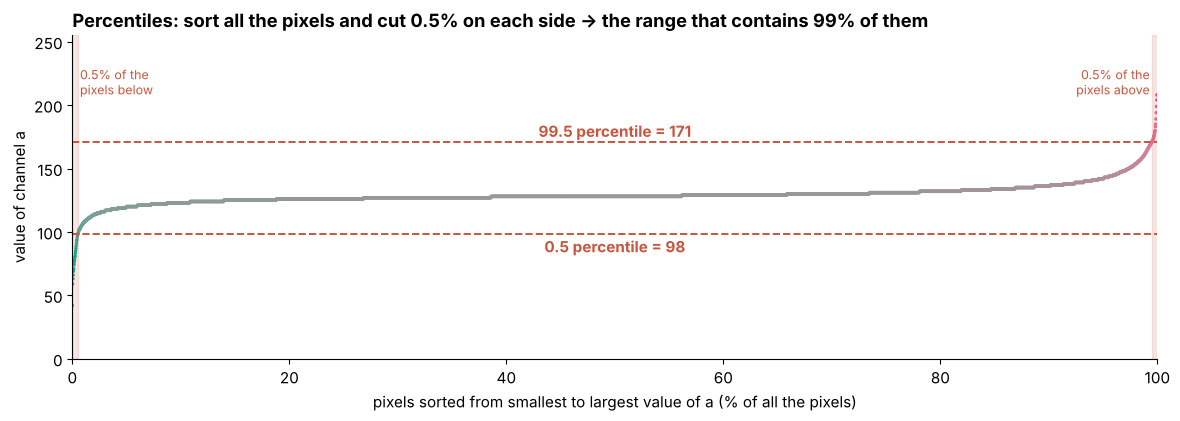

In [3]:
vals = np.sort(LAB_PIX[:, 1])
lo, hi = np.percentile(vals, [0.5, 99.5])
fig, ax = plt.subplots(figsize=(14, 4.2))
pos = np.linspace(0, 100, len(vals))
step = max(1, len(vals) // 4000)
ax.scatter(pos[::step], vals[::step], s=6, c=colour_strip("LAB", 1)[0][vals[::step].astype(int)] / 255, lw=0)
ax.axvspan(0, 0.5, color=RED, alpha=0.15); ax.axvspan(99.5, 100, color=RED, alpha=0.15)
for p, v in [(0.5, lo), (99.5, hi)]:
    ax.axhline(v, color=RED, ls="--", lw=1.4)
    ax.text(50, v + (4 if p > 50 else -14), f"{p} percentile = {v:.0f}", color=RED, ha="center", fontweight="bold")
ax.text(0.7, 230, "0.5% of the\npixels below", color=RED, fontsize=9, va="top")
ax.text(99.3, 230, "0.5% of the\npixels above", color=RED, fontsize=9, va="top", ha="right")
ax.set_xlabel("pixels sorted from smallest to largest value of a (% of all the pixels)")
ax.set_ylabel("value of channel a"); ax.set_ylim(0, 255); ax.set_xlim(0, 100)
ax.set_title("Percentiles: sort all the pixels and cut 0.5% on each side → the range that contains 99% of them", loc="left")
plt.savefig(FIG / "ranges_2_percentiles.png"); plt.show()

The curve is almost **flat**: from the 1st to the 99th pixel percentage, the value of `a` barely moves. That flat part is
where the paintings live, and it is where we want our bins.

## 3. Uniform bins vs range-adapted bins

Same data, same number of bins (8), two ways of placing them:
- **uniform:** 8 bins of equal width over 0–255 (each bin = 32 values);
- **range-adapted:** 8 bins of equal width, but only between the 0.5 and 99.5 percentiles. Pixels outside go to the
  first / last bin.

The number on top of each bin is the % of pixels that fall in it.

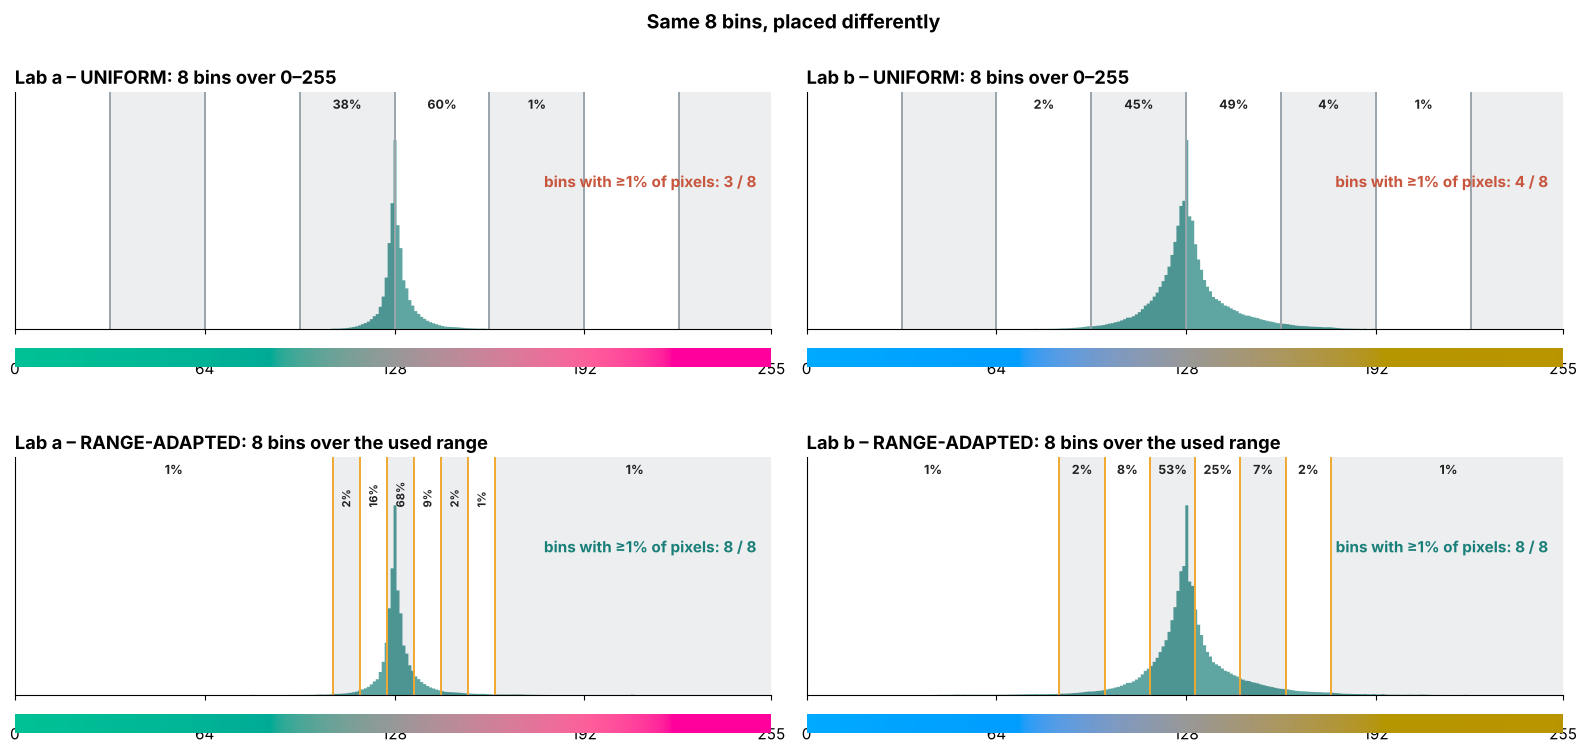

In [4]:
def uniform_edges(n):
    return np.linspace(0, 256, n + 1)


def range_edges(values, n):
    lo, hi = np.percentile(values, [0.5, 99.5])
    e = np.linspace(lo, hi, n + 1)
    e[0], e[-1] = 0, 256
    return e


NB = 8
fig, axes = plt.subplots(2, 2, figsize=(16, 7.5))
for col, (c, name) in enumerate([(1, "a"), (2, "b")]):
    v = LAB_PIX[:, c]
    channel_plot(axes[0, col], v, "LAB", c, f"Lab {name} – UNIFORM: 8 bins over 0–255", uniform_edges(NB), GREY, show_pct=True)
    channel_plot(axes[1, col], v, "LAB", c, f"Lab {name} – RANGE-ADAPTED: 8 bins over the used range", range_edges(v, NB), ORANGE, show_pct=True)
    used_u = sum(((v >= a) & (v < b)).mean() >= 0.01 for a, b in zip(uniform_edges(NB)[:-1], uniform_edges(NB)[1:]))
    e = range_edges(v, NB)
    used_r = sum(((v >= a) & (v < b)).mean() >= 0.01 for a, b in zip(e[:-1], e[1:]))
    axes[0, col].text(250, axes[0, col].get_ylim()[1] * 0.6, f"bins with ≥1% of pixels: {used_u} / {NB}", ha="right", color=RED, fontweight="bold")
    axes[1, col].text(250, axes[1, col].get_ylim()[1] * 0.6, f"bins with ≥1% of pixels: {used_r} / {NB}", ha="right", color=TEAL, fontweight="bold")
plt.suptitle("Same 8 bins, placed differently", fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout(h_pad=3.5); plt.savefig(FIG / "ranges_3_uniform_vs_range.png"); plt.show()

- **Uniform:** almost all the pixels fall in **2–3 bins** (those touching 128); the other bins are empty. With 8 bins we
  only have 2–3 "colour levels" in practice.
- **Range-adapted:** the same 8 bins are all inside the window where the pixels are, so all of them are used and the
  histogram distinguishes 8 levels of colour instead of 2–3.

## 4. What the histogram "sees"

A histogram only knows **in which bin** each pixel falls. If we repaint every pixel with the colour of the **centre of its
bin**, we see the image exactly as the histogram sees it. Lab, 4 bins for L and 8 for a and b (256 cells), on two paintings.

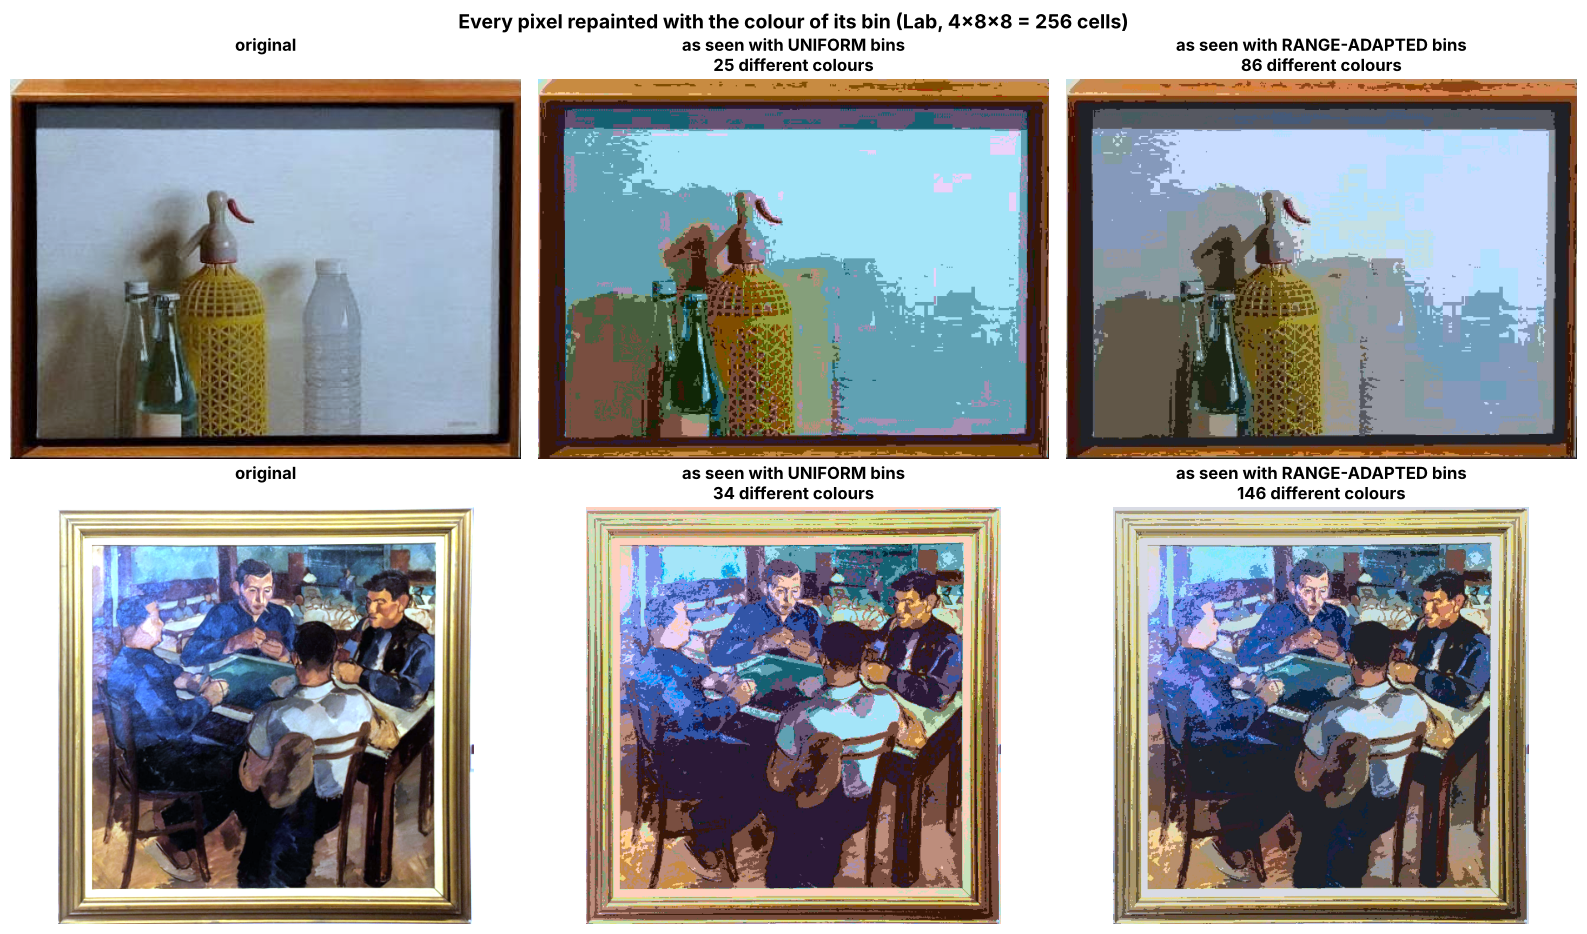

In [5]:
def bin_centres(edges):
    c = (edges[:-1] + edges[1:]) / 2
    c[0] = (max(edges[1] - (edges[2] - edges[1]), 0) + edges[1]) / 2 if len(edges) > 2 else c[0]
    c[-1] = (edges[-2] + min(edges[-2] + (edges[-2] - edges[-3]), 255)) / 2 if len(edges) > 2 else c[-1]
    return c


def as_seen(img_bgr, edges_per_channel):
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB).astype(float)
    out = np.empty_like(lab)
    for c, e in enumerate(edges_per_channel):
        idx = np.clip(np.searchsorted(e[1:-1], lab[..., c], side="right"), 0, len(e) - 2)
        out[..., c] = bin_centres(e)[idx]
    return cv2.cvtColor(np.clip(out, 0, 255).astype(np.uint8), cv2.COLOR_LAB2BGR)


BINS = (4, 8, 8)
E_UNI = [uniform_edges(n) for n in BINS]
E_RNG = [range_edges(LAB_PIX[:, c], n) for c, n in enumerate(BINS)]
examples = [channel_mean_128(resize_max(cv2.imread(str(QSD1_DIR / f"{i:05d}.jpg")), 500)) for i in (2, 12)]

fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
for r, img in enumerate(examples):
    for ax, (im, title) in zip(axes[r], [(img, "original"), (as_seen(img, E_UNI), "as seen with UNIFORM bins"),
                                         (as_seen(img, E_RNG), "as seen with RANGE-ADAPTED bins")]):
        ax.imshow(im[..., ::-1]); ax.axis("off")
        n_colours = len(np.unique(im.reshape(-1, 3), axis=0)) if im is not img else None
        ax.set_title(title + (f"\n{n_colours} different colours" if n_colours else "\n"), fontsize=12)
plt.suptitle(f"Every pixel repainted with the colour of its bin (Lab, {BINS[0]}×{BINS[1]}×{BINS[2]} = 256 cells)", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "ranges_4_what_the_histogram_sees.png"); plt.show()

With **uniform** bins, all the soft colours of the painting fall into the 2–3 bins around 128, and each of those bins is
very wide (32 values): very different tones end up in the same bin, and the colour of the bin is far from the real one
(the grey wall of the still life becomes cyan). The histogram only distinguishes **25 colours**. With **range-adapted**
bins, the same 256 cells are all placed where the colours of paintings are: the tones stay close to the original and the
histogram distinguishes **86 colours** (146 vs 34 in the second painting), so it can tell more paintings apart.

## 5. Effect on a real 3D histogram

How many of the 256 cells of the 3D histogram receive at least one pixel, for every painting of the BBDD?

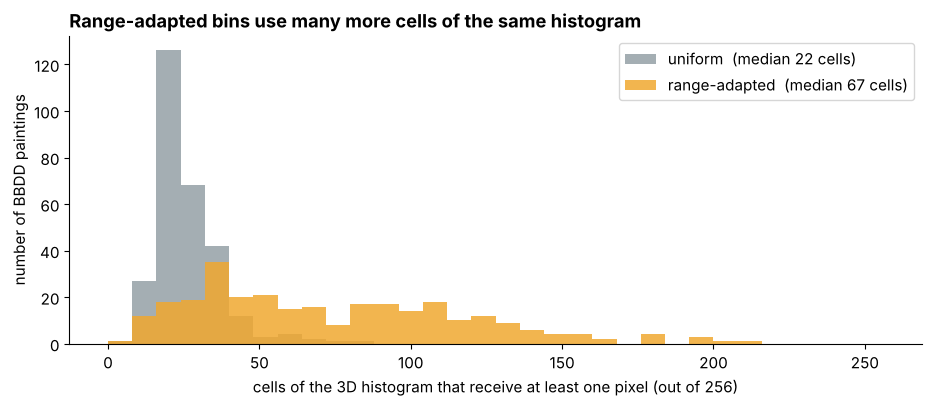

In [6]:
def cells_used(img_bgr, edges):
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    idx = [np.clip(np.searchsorted(e[1:-1], lab[..., c], side="right"), 0, len(e) - 2) for c, e in enumerate(edges)]
    flat = (idx[0] * BINS[1] + idx[1]) * BINS[2] + idx[2]
    return len(np.unique(flat))


used_u = np.array([cells_used(x, E_UNI) for x in BBDD])
used_r = np.array([cells_used(x, E_RNG) for x in BBDD])
fig, ax = plt.subplots(figsize=(11, 4))
bins_h = np.arange(0, 257, 8)
ax.hist(used_u, bins=bins_h, color=GREY, alpha=0.9, label=f"uniform  (median {np.median(used_u):.0f} cells)")
ax.hist(used_r, bins=bins_h, color=ORANGE, alpha=0.85, label=f"range-adapted  (median {np.median(used_r):.0f} cells)")
ax.set_xlabel("cells of the 3D histogram that receive at least one pixel (out of 256)"); ax.set_ylabel("number of BBDD paintings")
ax.legend(); ax.set_title("Range-adapted bins use many more cells of the same histogram", loc="left")
plt.savefig(FIG / "ranges_5_cells_used.png"); plt.show()

Same size of histogram (256 numbers), but with uniform bins most paintings only use a few dozen cells; with
range-adapted bins they use several times more. More cells in use = a more detailed description of the colours.

## 6. Effect on retrieval

Results of experiment 3.3 in `c1-week2.ipynb` (global 3D histograms, mean of QSD1 + QSD2-GT = 60 queries, MRR, best
of χ² and Hellinger). These numbers are copied from that notebook.

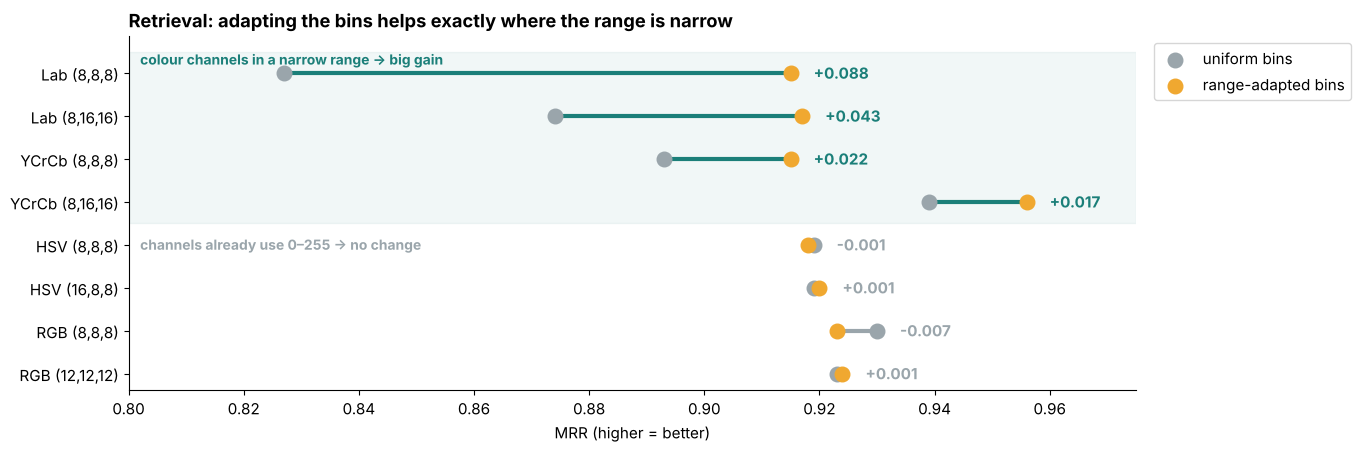

In [7]:
RESULTS = {   # (space, bins): (uniform, range, quantile) – from c1-week2.ipynb §3.3
    "Lab (8,8,8)": (0.827, 0.915, 0.915), "Lab (8,16,16)": (0.874, 0.917, 0.897),
    "YCrCb (8,8,8)": (0.893, 0.915, 0.919), "YCrCb (8,16,16)": (0.939, 0.956, 0.931),
    "HSV (8,8,8)": (0.919, 0.918, 0.919), "HSV (16,8,8)": (0.919, 0.920, 0.918),
    "RGB (8,8,8)": (0.930, 0.923, 0.928), "RGB (12,12,12)": (0.923, 0.924, 0.935),
}
names = list(RESULTS)
uni = np.array([RESULTS[n][0] for n in names]); rng = np.array([RESULTS[n][1] for n in names])
fig, ax = plt.subplots(figsize=(13, 4.6))
y = np.arange(len(names))[::-1]
for yi, u, r in zip(y, uni, rng):
    ax.plot([u, r], [yi, yi], color=TEAL if r > u + 0.01 else GREY, lw=3, zorder=1)
ax.scatter(uni, y, s=110, color=GREY, zorder=2, label="uniform bins")
ax.scatter(rng, y, s=110, color=ORANGE, zorder=3, label="range-adapted bins")
for yi, u, r in zip(y, uni, rng):
    ax.text(max(u, r) + 0.004, yi, f"{r - u:+.3f}", va="center", fontweight="bold", color=TEAL if r > u + 0.01 else GREY)
ax.set_yticks(y, names); ax.set_xlabel("MRR (higher = better)"); ax.set_xlim(0.8, 0.975)
ax.axhspan(3.5, 7.5, color=TEAL, alpha=0.06)
ax.text(0.802, 7.2, "colour channels in a narrow range → big gain", color=TEAL, fontweight="bold", fontsize=10)
ax.text(0.802, 3.2, "channels already use 0–255 → no change", color=GREY, fontweight="bold", fontsize=10, va="top")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0)); ax.set_title("Retrieval: adapting the bins helps exactly where the range is narrow", loc="left")
plt.savefig(FIG / "ranges_6_retrieval.png"); plt.show()

**Summary (for the slide)**
- In Lab and YCrCb the colour channels of paintings use only a narrow window around 128 (99% of the pixels in e.g. 98–171).
- With uniform bins over 0–255, most colour bins are empty and all the colours of a painting are squeezed into 2–3 bins:
  the histogram distinguishes 3–4 times fewer colours.
- **Range-adapted bins** = the same number of bins, placed between the 0.5 and 99.5 percentiles of the BBDD pixels.
- Result: Lab MRR 0.827 → 0.915, YCrCb 0.893 → 0.915 (and 0.956 with (8, 16, 16)); HSV and RGB do not change, which
  confirms that the gain comes from the empty bins.